<a href="https://colab.research.google.com/github/2DObjectDetector/T21/blob/main/Emma_Sloan_Ass2_T21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Set-Up


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!rm -rf /content/kitti3k_yolo
!cp -r /content/drive/MyDrive/kitti3k_yolo /content/kitti3k_yolo
dataset_yaml = "/content/kitti3k_yolo/kitti3k.yaml"

# install YOLO
!pip install -U ultralytics
from ultralytics import YOLO
model = YOLO("yolo11n.pt")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Evaluate pre-trained model

In [ ]:


# evaluate the pretrained model on the car class only, using the test split

pretrained_val_metrics = model.val(
    data=dataset_yaml,
    split="test",
    classes=[2],
    imgsz=640,
    conf=0.001,
    iou=0.7,
    exist_ok=True
)

Ultralytics 8.4.124 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3585.2±1036.9 MB/s, size: 826.4 KB)
val: Scanning /content/kitti3k_yolo/labels/test... 450 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 450/450 435.2it/s 1.0s
val: New cache created: /content/kitti3k_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 29/29 2.2it/s 13.5s
                   all        450       1795      0.784      0.625      0.713      0.405
                   car        394       1795      0.784      0.625      0.713      0.405
Speed: 1.7ms preprocess, 3.9ms inference, 0.0ms loss, 4.9ms postprocess per image
Results saved to /content/runs/detect/val


# Generate PR curve for the car class

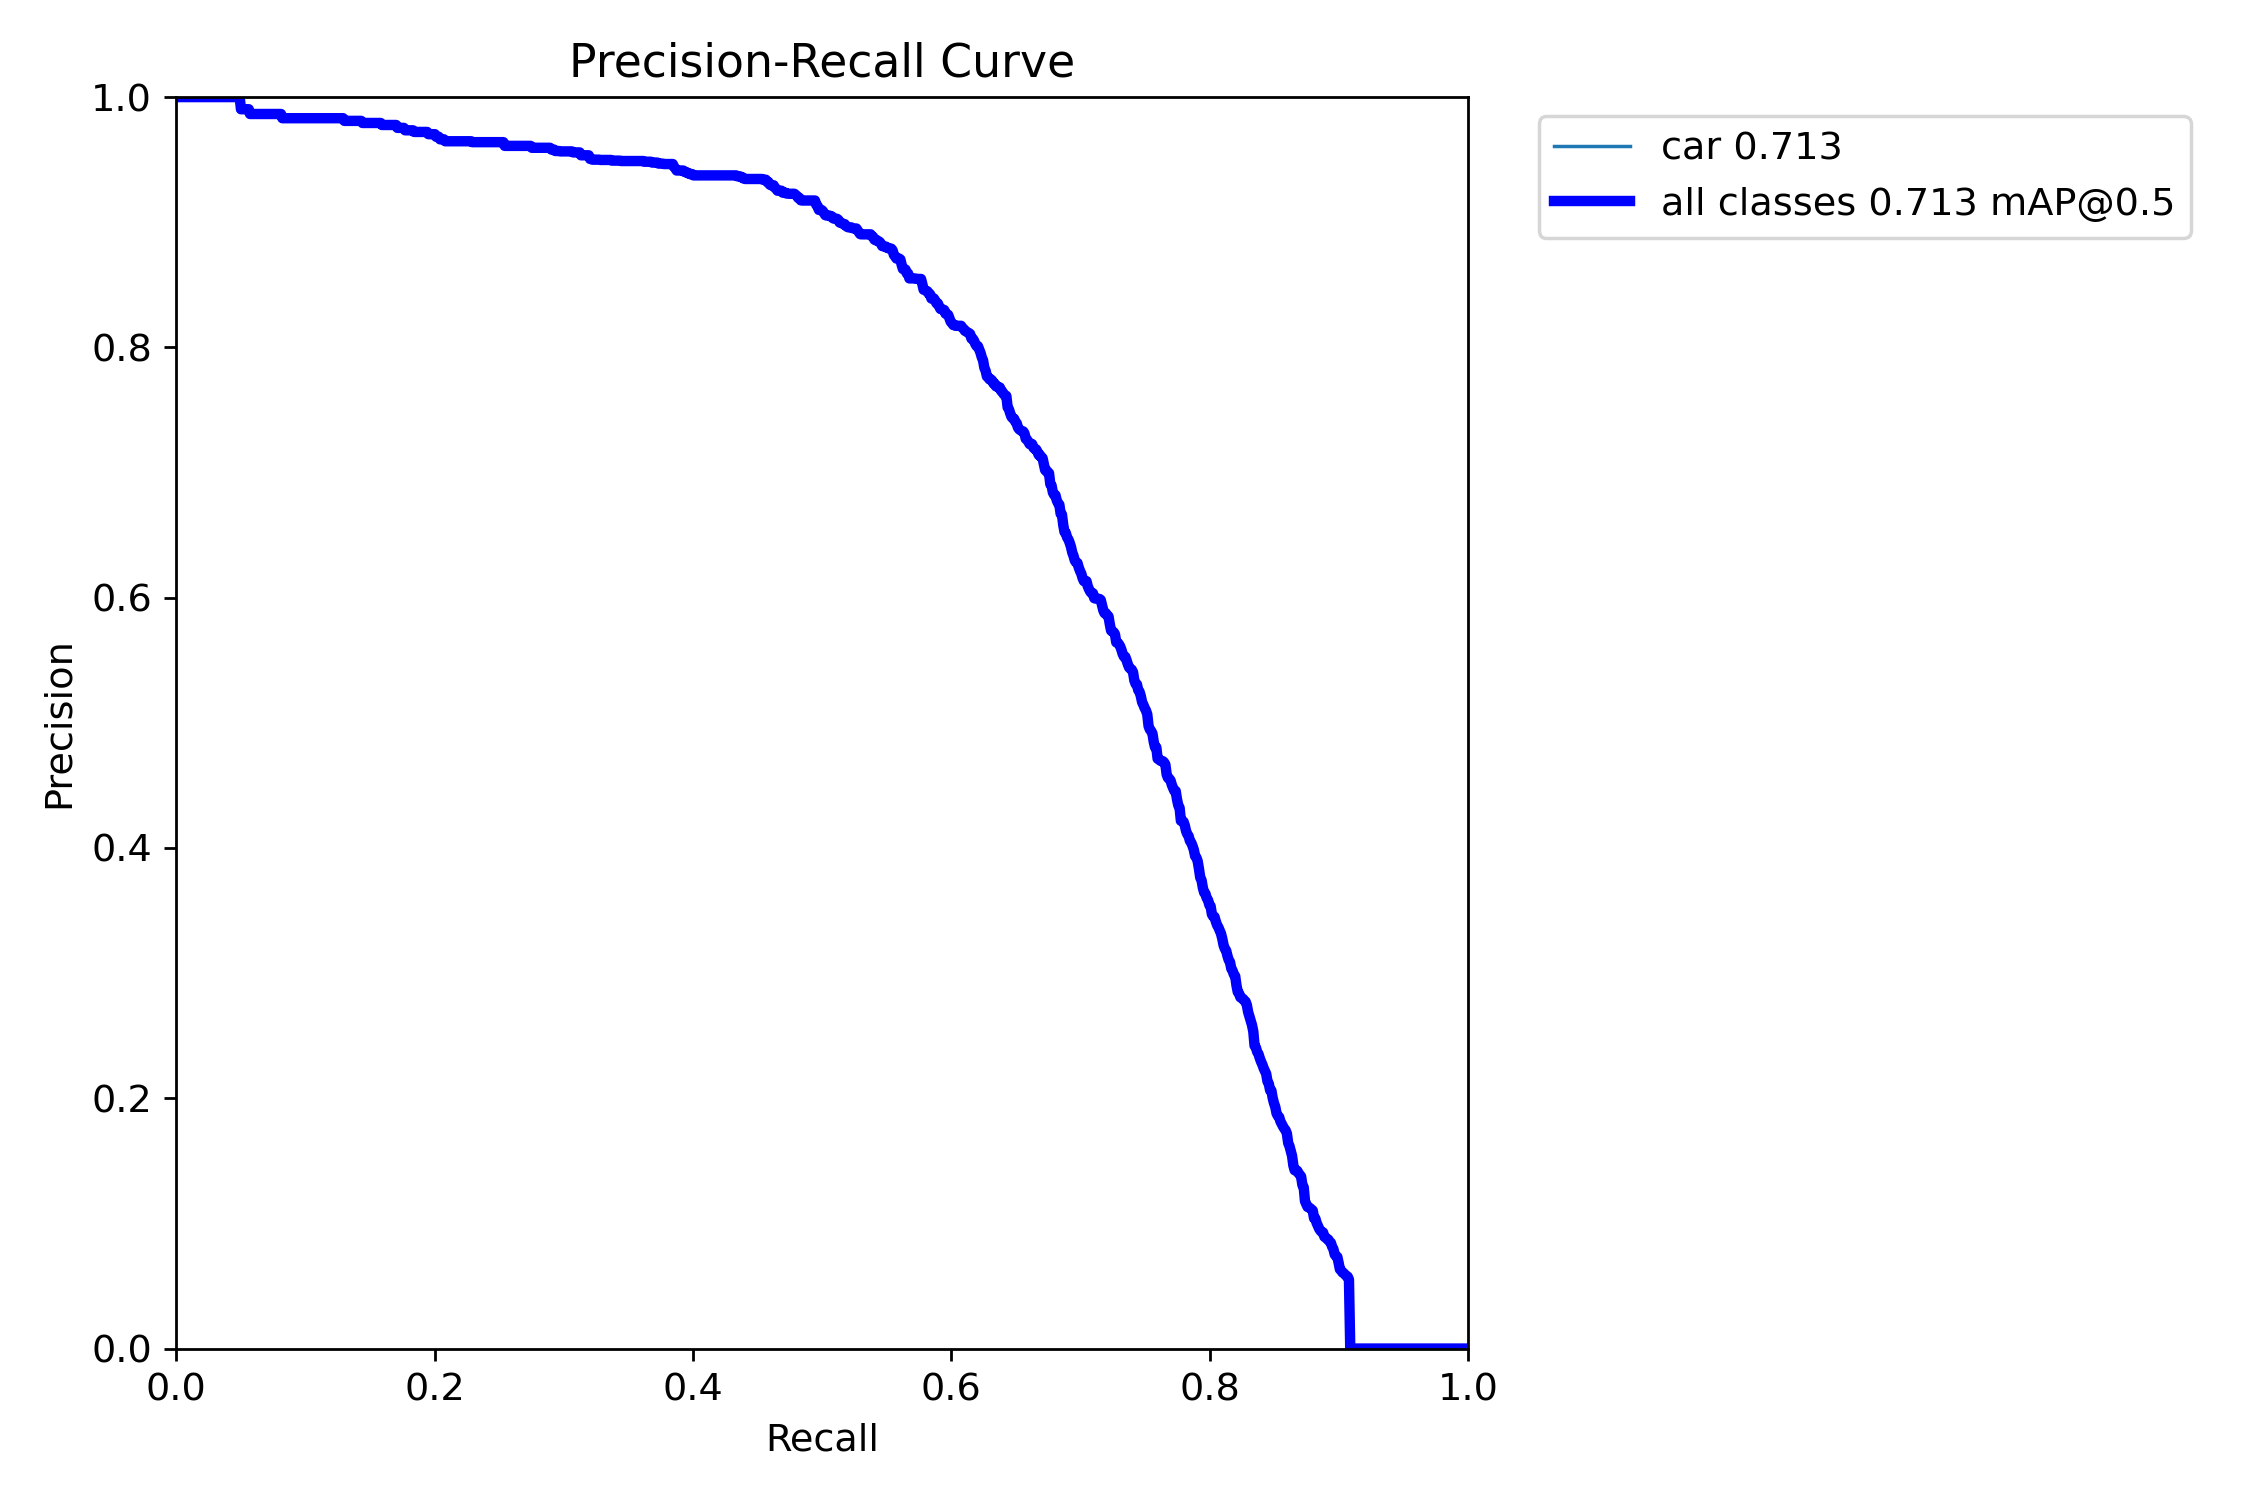

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/runs/detect/val/BoxPR_curve.png"))

In [ ]:

print(f"Car AP50: {pretrained_val_metrics.box.map50:.3f}")
print(f"Car AP50-95: {pretrained_val_metrics.box.map:.3f}")

Car AP50: 0.713
Car AP50-95: 0.405
